<a href="https://colab.research.google.com/github/Tonioord/TGVH-DS/blob/main/TGVH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import pandas as pd
import plotly.express as px

In [5]:
url_github= "https://github.com/Tonioord/TGVH-DS/raw/refs/heads/main/ExportacionGit.csv"
df = pd.read_csv(url_github, encoding='latin-1')

In [16]:
print(f"Dimensiones del dataset: {df.shape}")
display(df.head())

Dimensiones del dataset: (4462, 22)


,AGENDA,TIPO VISITA,FECHA,INICIO,MASCOTA,RESPONSABLE VISITA,ESPECIE,RAZA,ASUNTO,MASCOTA_SEXO,...,USUARIO CREACIÓN CITA,USUARIO MODIFICACIÓN CITA,PROCEDENCIA,COMUNICACION_IDCLIENTE,COMUNICACION_IDANIMAL,FECHA_DT,FECHA_CREACION_DT,HORA_INICIO,DIA_SEMANA,ASUNTO_LIMPIO
0,MEDICINA FELINA,CONSULTA GENERAL SEGUIMIENTO,27/02/2026,11:00,TERPENA ESCOBAR,Carmen Lizzeth Espinosa Fuentez,FELINA,EUROPEO DE PELO CORTO,CONSULTA POR LLAMADA,HEMBRA,...,Montserrat Hernández Betancourt,Montserrat Hernández Betancourt,NaN,831252,831253,2026-02-27,2026-03-26 18:45:00,11,Friday,NaN
1,MEDICINA INTERNA CANINOS,CONSULTA GENERAL SEGUIMIENTO,02/03/2026,10:00,DUMPLING ORTIZ,Brenda Nicole Suárez González,CANINA,MESTIZO,SEGUIMIENTO,HEMBRA,...,Brenda Nicole Suárez González,NaN,NaN,830385,830386,2026-03-02,2026-03-02 10:00:00,10,Monday,SEGUIMIENTO
2,MEDICINA INTERNA CANINOS,CONSULTA GENERAL,02/03/2026,10:29,MOLLY,Brenda Nicole Suárez González,CANINA,POMERANIA,2DA OPINION,HEMBRA,...,Brenda Nicole Suárez González,NaN,NaN,830390,830391,2026-03-02,2026-03-02 10:30:00,10,Monday,NaN
3,MEDICINA INTERNA CANINOS,CONSULTA GENERAL,02/03/2026,13:00,KAI SAAVEDRA,Livier Delgadillo Quezada,CANINA,GOLDEN RETRIEVER,CONSULTA GENERAL,MACHO,...,Monica Abigail Hernandez Nava,NaN,NaN,830404,830406,2026-03-02,2026-03-02 12:54:00,13,Monday,NaN
4,MEDICINA INTERNA CANINOS,CONSULTA GENERAL,02/03/2026,14:00,DUKE ARROYO,Hugo Enrique Romero Ambris,CANINA,HUSKY SIBERIANO,CONSULTA GENERAL,MACHO,...,Monica Abigail Hernandez Nava,NaN,NaN,830407,830408,2026-03-02,2026-03-02 13:52:00,14,Monday,NaN


In [10]:
# 2. Limpiar nombres de columnas (quitar espacios en blanco al inicio o final)
df.columns = df.columns.str.strip()

# 3. Conversión de Fechas (Cuidado con los formatos)
# Convertimos a formato fecha para poder extraer meses, días y calcular tiempos
df['FECHA_DT'] = pd.to_datetime(df['FECHA'], format='%d/%m/%Y', errors='coerce')
df['FECHA_CREACION_DT'] = pd.to_datetime(df['FECHA CREACION CITA'], errors='coerce')
df['HORA_INICIO'] = pd.to_datetime(df['INICIO'], format='%H:%M', errors='coerce').dt.hour

# 4. Estandarización de Texto
# Columnas que necesitamos unificar para evitar conteos duplicados
columnas_texto = ['AGENDA', 'TIPO VISITA', 'ESPECIE', 'RAZA', 'ASUNTO', 'MASCOTA_SEXO']
for col in columnas_texto:
    # Convertir a string, quitar espacios en los bordes y pasar a mayúsculas
    df[col] = df[col].astype(str).str.strip().str.upper()

# 5. Normalización agresiva de la columna 'ASUNTO'
# Mapeamos las variaciones de recepción a categorías limpias
mapeo_asuntos = {
    'CONSULTA DE 1RA VEZ': 'PRIMERA VEZ',
    'CONSULTA DE PRIMERA VEZ': 'PRIMERA VEZ',
    'CONSULTA DE SEGUIMIENTO': 'SEGUIMIENTO',
    'REVISION': 'SEGUIMIENTO'
}
df['ASUNTO_LIMPIO'] = df['ASUNTO'].replace(mapeo_asuntos)

# Identificar con una bandera si la consulta contiene la palabra seguimiento o primera vez
df.loc[df['ASUNTO'].str.contains('SEGUIMIENTO', na=False), 'ASUNTO_LIMPIO'] = 'SEGUIMIENTO'
df.loc[df['ASUNTO'].str.contains('1RA VEZ|PRIMERA VEZ', na=False), 'ASUNTO_LIMPIO'] = 'PRIMERA VEZ'

# 6. Eliminar registros basura
df = df.dropna(subset=['FECHA_DT']) # Quitar filas sin fecha válida
df = df.drop_duplicates()           # Quitar filas idénticas duplicadas por error del sistema

# Mostrar el resultado
print(f"Dimensiones de la base limpia: {df.shape}")
print("\nEjemplo de los primeros 3 registros limpios:")
display(df[['FECHA_DT', 'HORA_INICIO', 'ESPECIE', 'RAZA', 'ASUNTO_LIMPIO']].head(3))

/tmp/ipykernel_619/1891887063.py:7: UserWarning: Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['FECHA_CREACION_DT'] = pd.to_datetime(df['FECHA CREACION CITA'], errors='coerce')


Dimensiones de la base limpia: (4462, 21)

Ejemplo de los primeros 3 registros limpios:


,FECHA_DT,HORA_INICIO,ESPECIE,RAZA,ASUNTO_LIMPIO
0,2026-02-27,11,FELINA,EUROPEO DE PELO CORTO,CONSULTA POR LLAMADA
1,2026-03-02,10,CANINA,MESTIZO,SEGUIMIENTO
2,2026-03-02,10,CANINA,POMERANIA,2DA OPINION


/tmp/ipykernel_619/2361433685.py:16: UserWarning:

Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.

/tmp/ipykernel_619/2361433685.py:40: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




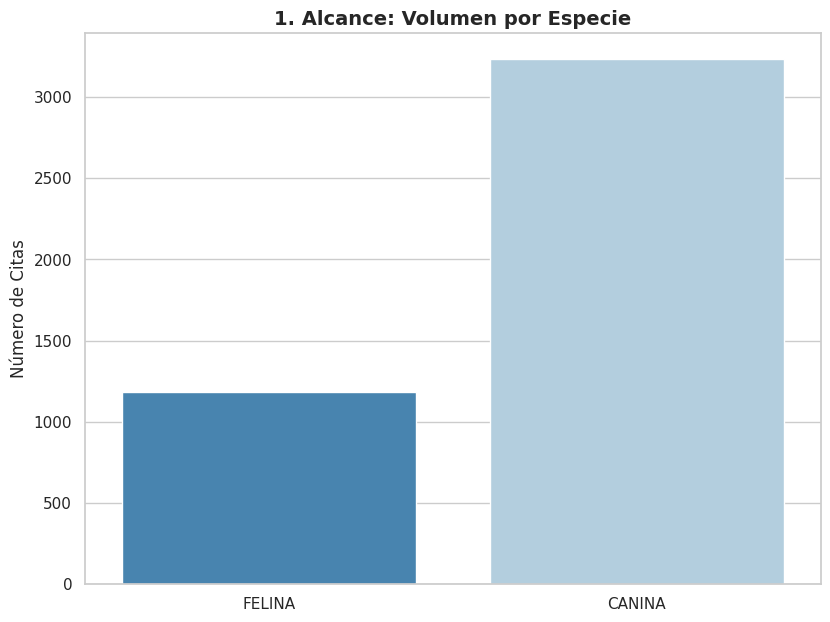

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual de Seaborn
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (16, 24)

# 1. Cargar y limpiar datos
url = "https://github.com/Tonioord/TGVH-DS/raw/refs/heads/main/ExportacionGit.csv"
df = pd.read_csv(url, encoding='latin-1')
df.columns = df.columns.str.strip()

df['FECHA_DT'] = pd.to_datetime(df['FECHA'], format='%d/%m/%Y', errors='coerce')
df['FECHA_CREACION_DT'] = pd.to_datetime(df['FECHA CREACION CITA'], errors='coerce')
df['HORA_INICIO'] = pd.to_datetime(df['INICIO'], format='%H:%M', errors='coerce').dt.hour
df['DIA_SEMANA'] = df['FECHA_DT'].dt.day_name()

for col in ['AGENDA', 'TIPO VISITA', 'ESPECIE', 'RAZA', 'ASUNTO', 'MASCOTA_SEXO']:
    df[col] = df[col].astype(str).str.strip().str.upper()

df.loc[df['ASUNTO'].str.contains('SEGUIMIENTO', na=False), 'ASUNTO_LIMPIO'] = 'SEGUIMIENTO'
df.loc[df['ASUNTO'].str.contains('1RA VEZ|PRIMERA VEZ', na=False), 'ASUNTO_LIMPIO'] = 'PRIMERA VEZ'
df = df.dropna(subset=['FECHA_DT']).drop_duplicates()

# Cálculo de Lead Time (Anticipación)
df_valid = df.dropna(subset=['FECHA_CREACION_DT']).copy()
df_valid['LEAD_TIME'] = (df_valid['FECHA_DT'] - df_valid['FECHA_CREACION_DT'].dt.normalize()).dt.days
df_valid = df_valid[df_valid['LEAD_TIME'] >= 0]

# ==========================================
# CREACIÓN DEL DASHBOARD CON SEABORN
# ==========================================
fig = plt.figure()
fig.subplots_adjust(hspace=0.5, wspace=0.3)

# 1. Alcance
ax1 = plt.subplot(4, 2, 1)
sns.countplot(data=df[df['ESPECIE'].isin(['CANINA', 'FELINA'])], x='ESPECIE', palette='Blues_r', ax=ax1)
ax1.set_title('1. Alcance: Volumen por Especie', fontsize=14, fontweight='bold')
ax1.set_ylabel('Número de Citas')
ax1.set_xlabel('')

plt.tight_layout()
plt.show()

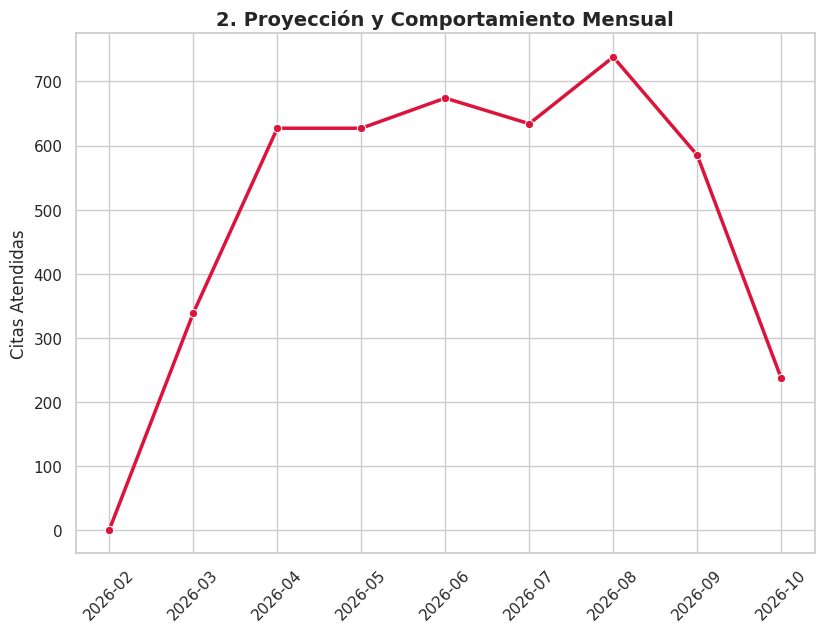

In [25]:
# 2. Comportamiento Mensual
ax2 = plt.subplot(4, 2, 2)
df_mensual = df['FECHA_DT'].dt.to_period('M').value_counts().sort_index().reset_index()
df_mensual.columns = ['Mes', 'Citas']
df_mensual['Mes'] = df_mensual['Mes'].astype(str)
sns.lineplot(data=df_mensual, x='Mes', y='Citas', marker='o', color='crimson', linewidth=2.5, ax=ax2)
ax2.set_title('2. Proyección y Comportamiento Mensual', fontsize=14, fontweight='bold')
ax2.tick_params(axis='x', rotation=45)
ax2.set_ylabel('Citas Atendidas')
ax2.set_xlabel('')


plt.tight_layout()
plt.show()

/tmp/ipykernel_619/4134451714.py:4: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




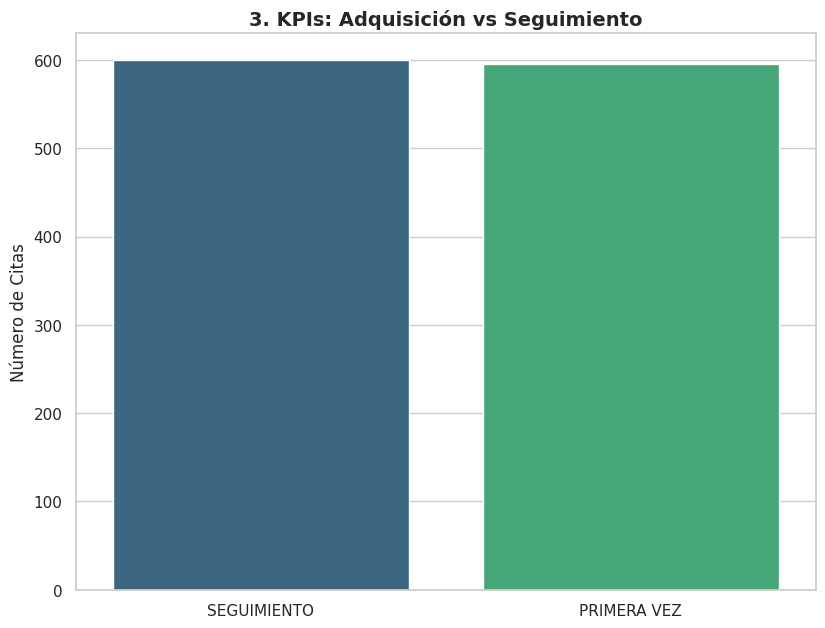

In [26]:

# 3. KPIs: Primera Vez vs Seguimiento
ax3 = plt.subplot(4, 2, 3)
kpi_data = df[df['ASUNTO_LIMPIO'].isin(['SEGUIMIENTO', 'PRIMERA VEZ'])]
sns.countplot(data=kpi_data, x='ASUNTO_LIMPIO', palette='viridis', ax=ax3)
ax3.set_title('3. KPIs: Adquisición vs Seguimiento', fontsize=14, fontweight='bold')
ax3.set_xlabel('')
ax3.set_ylabel('Número de Citas')

plt.tight_layout()
plt.show()

In [ ]:
# 4. Retención y Lealtad
ax4 = plt.subplot(4, 2, 4)
citas_por_paciente = df['COMUNICACION_IDANIMAL'].value_counts()
lealtad = pd.DataFrame({
    'Tipo': ['1 Sola Visita', 'Recurrentes (>1)'],
    'Pacientes': [(citas_por_paciente==1).sum(), (citas_por_paciente>1).sum()]
})
sns.barplot(data=lealtad, x='Tipo', y='Pacientes', palette='magma', ax=ax4)
ax4.set_title('4. Nivel de Retención de Pacientes', fontsize=14, fontweight='bold')
ax4.set_xlabel('')
ax4.set_ylabel('Pacientes Únicos')

# 5. Lead Time
ax5 = plt.subplot(4, 2, 5)
bins = [-1, 0, 3, 7, 100]
labels = ['Mismo Día', '1 a 3 Días', '4 a 7 Días', 'Más de 1 semana']
lead_time_cat = pd.cut(df_valid['LEAD_TIME'], bins=bins, labels=labels)
sns.countplot(y=lead_time_cat, palette='Set2', ax=ax5)
ax5.set_title('5. Comportamiento de Reserva (Lead Time)', fontsize=14, fontweight='bold')
ax5.set_xlabel('Número de Citas')
ax5.set_ylabel('Tiempo de Anticipación')

# 6. Heatmap Operativo
ax6 = plt.subplot(4, 2, 6)
dias_orden = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dias_es = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
heatmap_data = df.groupby(['DIA_SEMANA', 'HORA_INICIO']).size().unstack(fill_value=0)
heatmap_data = heatmap_data.reindex(dias_orden)
heatmap_data.index = dias_es
sns.heatmap(heatmap_data, cmap='YlOrRd', annot=True, fmt='g', cbar=True, ax=ax6)
ax6.set_title('6. Heatmap Operativo: Día vs Hora', fontsize=14, fontweight='bold')
ax6.set_ylabel('')
ax6.set_xlabel('Hora del Día')

# 7. Carga Operativa por Especialista
ax7 = plt.subplot(4, 2, (7, 8))
top_docs = df['RESPONSABLE VISITA'].value_counts().head(8).reset_index()
top_docs.columns = ['Médico', 'Citas Atendidas']
sns.barplot(data=top_docs, x='Citas Atendidas', y='Médico', palette='crest', ax=ax7)
ax7.set_title('7. Carga Operativa por Especialista (Top 8)', fontsize=14, fontweight='bold')
ax7.set_ylabel('')

plt.tight_layout()
plt.show()

In [ ]:
# 5. Lead Time
ax5 = plt.subplot(4, 2, 5)
bins = [-1, 0, 3, 7, 100]
labels = ['Mismo Día', '1 a 3 Días', '4 a 7 Días', 'Más de 1 semana']
lead_time_cat = pd.cut(df_valid['LEAD_TIME'], bins=bins, labels=labels)
sns.countplot(y=lead_time_cat, palette='Set2', ax=ax5)
ax5.set_title('5. Comportamiento de Reserva (Lead Time)', fontsize=14, fontweight='bold')
ax5.set_xlabel('Número de Citas')
ax5.set_ylabel('Tiempo de Anticipación')

plt.tight_layout()
plt.show()

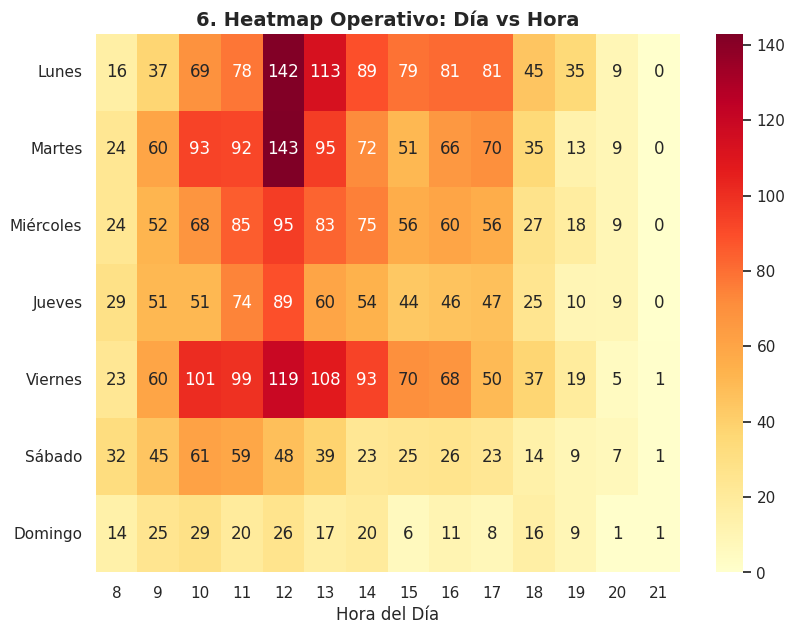

In [27]:
# 6. Heatmap Operativo
ax6 = plt.subplot(4, 2, 6)
dias_orden = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dias_es = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
heatmap_data = df.groupby(['DIA_SEMANA', 'HORA_INICIO']).size().unstack(fill_value=0)
heatmap_data = heatmap_data.reindex(dias_orden)
heatmap_data.index = dias_es
sns.heatmap(heatmap_data, cmap='YlOrRd', annot=True, fmt='g', cbar=True, ax=ax6)
ax6.set_title('6. Heatmap Operativo: Día vs Hora', fontsize=14, fontweight='bold')
ax6.set_ylabel('')
ax6.set_xlabel('Hora del Día')


plt.tight_layout()
plt.show()

/tmp/ipykernel_619/3238685983.py:5: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




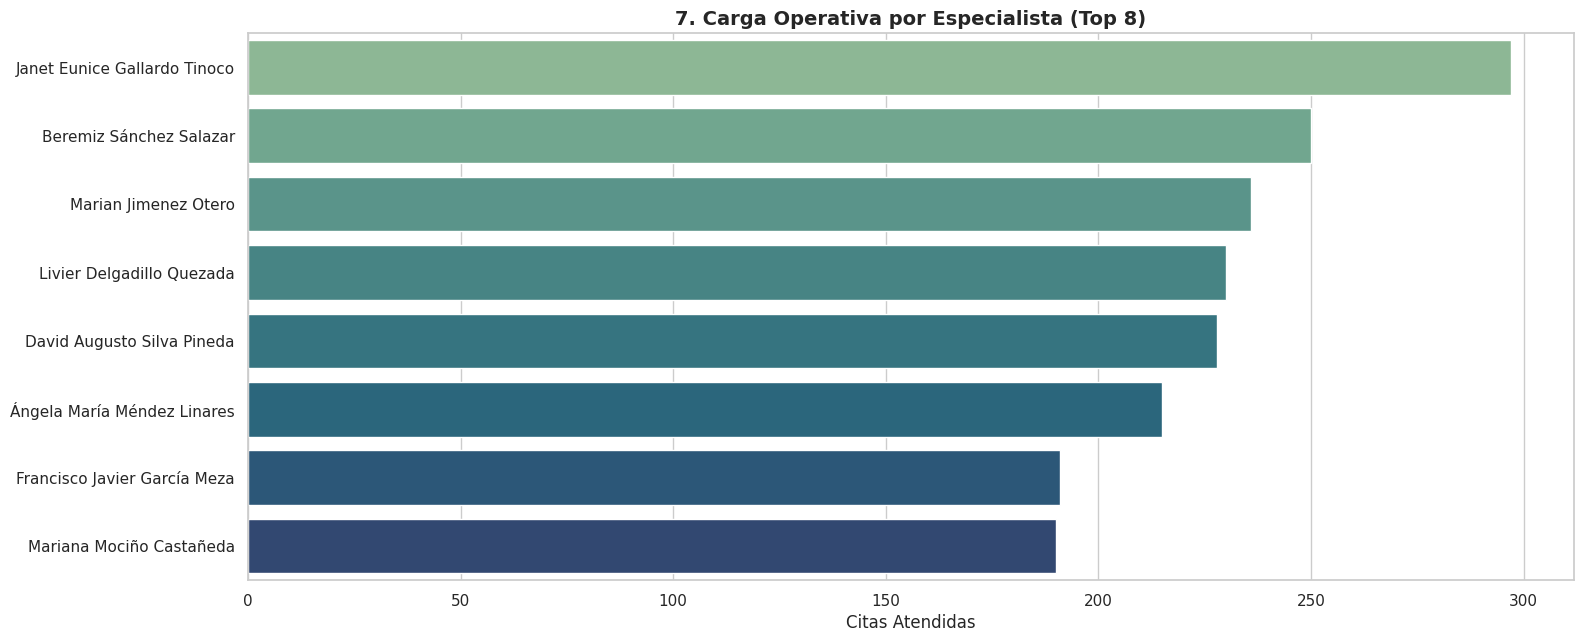

In [28]:
# 7. Carga Operativa por Especialista
ax7 = plt.subplot(4, 2, (7, 8))
top_docs = df['RESPONSABLE VISITA'].value_counts().head(8).reset_index()
top_docs.columns = ['Médico', 'Citas Atendidas']
sns.barplot(data=top_docs, x='Citas Atendidas', y='Médico', palette='crest', ax=ax7)
ax7.set_title('7. Carga Operativa por Especialista (Top 8)', fontsize=14, fontweight='bold')
ax7.set_ylabel('')

plt.tight_layout()
plt.show()

/tmp/ipykernel_619/4208513101.py:10: UserWarning:

Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.

/tmp/ipykernel_619/4208513101.py:43: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_619/4208513101.py:59: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




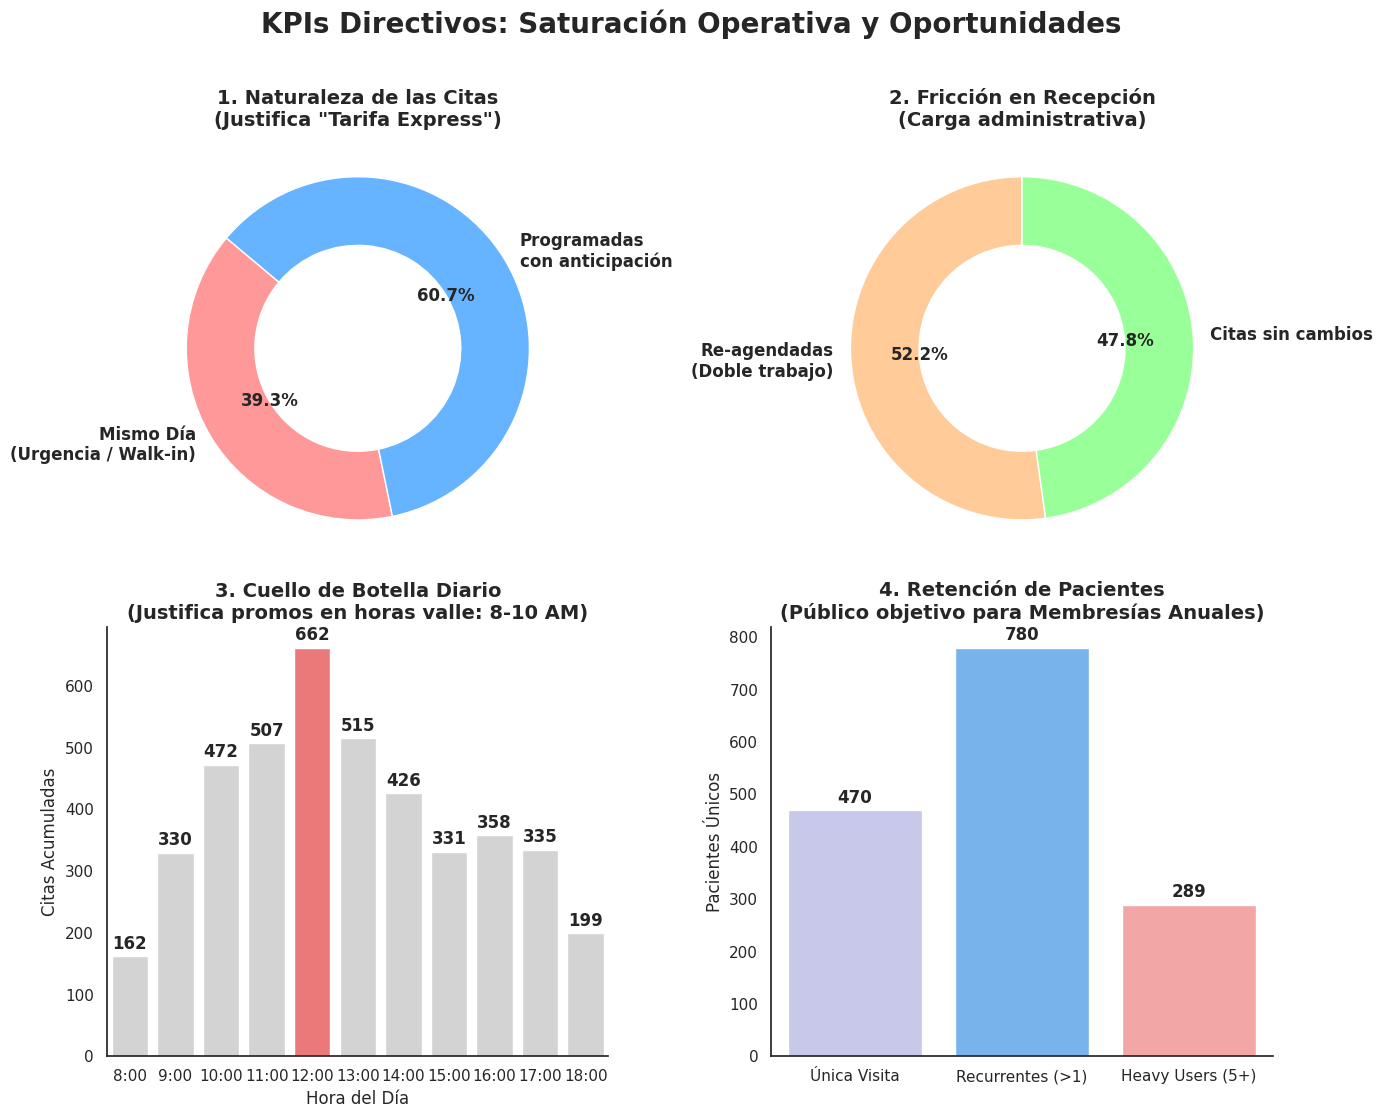

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar y preparar datos (Asegúrate de tener el link de tu GitHub)
url = "https://github.com/Tonioord/TGVH-DS/raw/refs/heads/main/ExportacionGit.csv"
df = pd.read_csv(url, encoding='latin-1')

df['FECHA_DT'] = pd.to_datetime(df['FECHA'], format='%d/%m/%Y', errors='coerce')
df['FECHA_CREACION_DT'] = pd.to_datetime(df['FECHA CREACION CITA'], errors='coerce')
df_valid = df.dropna(subset=['FECHA_DT', 'FECHA_CREACION_DT']).copy()
df_valid['LEAD_TIME'] = (df_valid['FECHA_DT'] - df_valid['FECHA_CREACION_DT'].dt.normalize()).dt.days
df_valid = df_valid[df_valid['LEAD_TIME'] >= 0]
df['HORA'] = pd.to_datetime(df['INICIO'], format='%H:%M', errors='coerce').dt.hour

# 2. Configurar el lienzo gigante y limpio
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('KPIs Directivos: Saturación Operativa y Oportunidades', fontsize=20, fontweight='bold', y=0.96)
sns.set_theme(style="white")

# ---- GRÁFICA 1: Naturaleza de las Citas (Tarifa Express) ----
mismo_dia = len(df_valid[df_valid['LEAD_TIME'] == 0])
programadas = len(df_valid[df_valid['LEAD_TIME'] > 0])
axes[0, 0].pie([mismo_dia, programadas], labels=['Mismo Día\n(Urgencia / Walk-in)', 'Programadas\ncon anticipación'],
               autopct='%1.1f%%', startangle=140, colors=['#ff9999','#66b3ff'],
               wedgeprops=dict(width=0.4, edgecolor='w'), textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[0, 0].set_title('1. Naturaleza de las Citas\n(Justifica "Tarifa Express")', fontsize=14, fontweight='bold')

# ---- GRÁFICA 2: Fricción en Recepción ----
modificadas = df['USUARIO MODIFICACIÓN CITA'].notna().sum()
intactas = len(df) - modificadas
axes[0, 1].pie([modificadas, intactas], labels=['Re-agendadas\n(Doble trabajo)', 'Citas sin cambios'],
               autopct='%1.1f%%', startangle=90, colors=['#ffcc99','#99ff99'],
               wedgeprops=dict(width=0.4, edgecolor='w'), textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[0, 1].set_title('2. Fricción en Recepción\n(Carga administrativa)', fontsize=14, fontweight='bold')

# ---- GRÁFICA 3: Cuello de Botella Diario ----
horas = df['HORA'].value_counts().sort_index()
horas = horas[(horas.index >= 8) & (horas.index <= 18)]
# Pintamos de rojo la hora pico (12), lo demás en gris
colors = ['lightgray' if h != 12 else '#ff6666' for h in horas.index]

sns.barplot(x=[f"{int(h)}:00" for h in horas.index], y=horas.values, palette=colors, ax=axes[1, 0])
axes[1, 0].set_title('3. Cuello de Botella Diario\n(Justifica promos en horas valle: 8-10 AM)', fontsize=14, fontweight='bold')
axes[1, 0].set_ylabel('Citas Acumuladas', fontsize=12)
axes[1, 0].set_xlabel('Hora del Día', fontsize=12)
# Poner los números arriba de cada barra
for p in axes[1, 0].patches:
    axes[1, 0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', xytext=(0, 9), textcoords='offset points', fontweight='bold')
sns.despine(ax=axes[1, 0])

# ---- GRÁFICA 4: Retención (Membresías) ----
citas_paciente = df['COMUNICACION_IDANIMAL'].value_counts()
una_visita = (citas_paciente == 1).sum()
mas_de_una = (citas_paciente > 1).sum()
heavy = (citas_paciente >= 5).sum() # 5 o más visitas

sns.barplot(x=['Única Visita', 'Recurrentes (>1)', 'Heavy Users (5+)'],
            y=[una_visita, mas_de_una, heavy],
            palette=['#c2c2f0', '#66b3ff', '#ff9999'], ax=axes[1, 1])
axes[1, 1].set_title('4. Retención de Pacientes\n(Público objetivo para Membresías Anuales)', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Pacientes Únicos', fontsize=12)
# Poner los números arriba de cada barra
for p in axes[1, 1].patches:
    axes[1, 1].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', xytext=(0, 9), textcoords='offset points', fontweight='bold')
sns.despine(ax=axes[1, 1])

# Mostrar todo junto
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

Reporte Ejecutivo: Análisis Operativo y Estrategia de Monetización
Fecha de Emisión: 10 de octubre de 2026
Área: Inteligencia de Negocios / Operaciones
Fuente de Datos: Sistema de Gestión QVET (Periodo Feb-Oct 2026)

Este documento presenta los hallazgos críticos sobre la capacidad operativa del hospital, identificando específicamente los factores que causan la saturación en el área de recepción. A partir de este diagnóstico, se estructuran cuatro iniciativas estratégicas diseñadas para optimizar el flujo de trabajo y capitalizar financieramente el comportamiento actual de los clientes.

Parte 1: Diagnóstico Operativo y Saturación de Recepción
El análisis de más de 4,400 registros transaccionales revela que el estrés operativo en el mostrador no se debe a una falta de personal, sino a un modelo de atención altamente reactivo y a procesos administrativos redundantes.

Fricción Administrativa Crítica (52.2% de Modificación de Citas): Más de la mitad de las citas creadas en el sistema requieren re-agendamientos, cambios de horario o reasignación de médicos. Esto significa que el personal de recepción invierte el doble de tiempo frente al monitor por cada paciente, reduciendo su capacidad para realizar cobros, ventas de mostrador o atención telefónica eficiente.

Modelo de Urgencia Encubierta (39.3% de Citas en el Mismo Día): El hospital opera bajo una dinámica de urgencias constante. Casi 4 de cada 10 pacientes llegan el mismo día en que se genera su registro. Esta falta de anticipación (Lead Time promedio de solo 2.1 días) destruye cualquier intento de planificación diaria y genera tiempos de espera prolongados que impactan la satisfacción del cliente.

Colapso de Capacidad Instalada (Pico de 12:00 PM): Existe un desequilibrio drástico en la distribución del tráfico. El volumen acumulado a las 12:00 PM (662 citas históricas) cuadruplica el flujo de la apertura a las 8:00 AM (162 citas). Al mediodía convergen los pacientes programados, los clientes sin cita (walk-ins) y los retrasos acumulados de la mañana, provocando un cuello de botella logístico severo.

Ceguera Comercial (97.6% de Omisión en Procedencia): La saturación operativa ha provocado que el equipo omita el registro del origen del cliente. Solo el 2.4% de la base de datos indica cómo se enteró el propietario del hospital. Esta fuga de información imposibilita medir el Retorno de Inversión (ROI) de cualquier campaña de marketing digital o publicidad física.

Parte 2: Plan de Acción y Estrategias de Facturación
Para mitigar los dolores operativos y transformar la carga de trabajo en ingresos tangibles, se propone la implementación inmediata de las siguientes cuatro estrategias de negocio.

1. Implementación de "Tarifa Express" (Monetización de la Inmediatez)
Dado que el 39.3% de la clientela exige atención el mismo día, se debe introducir un cobro premium por consultas sin cita previa.

Acción: Establecer un tabulador donde la "Consulta Express/Walk-in" tenga un sobreprecio del 15% al 20% respecto a la tarifa estándar programada.

Impacto Esperado: Inyección de capital inmediato por pacientes dispuestos a pagar por la urgencia, y una migración gradual de clientes sensibles al precio hacia el agendamiento anticipado, aliviando la carga sorpresa en recepción.

2. Desarrollo de Membresías Preventivas (Capitalización de Lealtad)
El hospital cuenta con una excelente tasa de retención del 62.4% y una cartera de 217 pacientes clasificados como "Heavy Users" (5 o más visitas en el periodo).

Acción: Diseñar y comercializar paquetes de "Salud Anual" pagados por adelantado (ej. que incluyan cuadro de vacunación, desparasitación y 2 revisiones generales).

Impacto Esperado: Aseguramiento de flujo de efectivo por anticipado y fidelización a largo plazo. Además, al garantizar la visita recurrente del paciente al hospital, se abren oportunidades constantes de cross-selling (venta cruzada) en estudios de laboratorio, imagenología (RX/Ultrasonido) y farmacia.

3. Precios Dinámicos por Franja Horaria (Optimización de Valles)
Para resolver el cuello de botella del mediodía y rentabilizar las horas muertas de la mañana, se debe aplicar un modelo tarifario basado en la demanda.

Acción: Lanzar una campaña permanente de incentivos (ej. 10% de descuento en profilaxis dental, esterilizaciones de rutina o estudios de imagenología) exclusivamente para citas agendadas entre las 08:00 AM y las 10:00 AM.

Impacto Esperado: Desplazamiento del tráfico de medicina preventiva hacia la mañana, liberando los consultorios a las 12:00 PM para atender urgencias rentables de tarifa completa y procedimientos de medicina interna.

4. Protocolo de "Agendamiento en Consultorio" (Cierre de Ciclo)
Actualmente, el peso de agendar los seguimientos recae enteramente en recepción, el área más saturada.

Acción: Modificar el flujo de trabajo en el sistema QVET para que sea responsabilidad obligatoria del médico tratante dejar agendada la próxima visita (fecha y hora exacta) antes de que el paciente salga del consultorio.

Impacto Esperado: Incremento automático en el volumen de consultas de seguimiento. Retira carga administrativa al personal de recepción, permitiéndoles enfocarse en la labor de cobro y cierre de venta en mostrador.

La ejecución escalonada de estas iniciativas permitirá al hospital recuperar el control sobre su agenda, reducir el estrés del personal de atención al cliente y generar un incremento directo en el ticket promedio por paciente.

In [31]:
# 1. Instalar la librería para crear PowerPoints (Ejecuta esta línea primero en Colab)
!pip install python-pptx

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pptx import Presentation
from pptx.util import Inches, Pt
import io

# 2. Cargar los datos y preparar gráficas con el NUEVO TONO
url = "https://github.com/Tonioord/TGVH-DS/raw/refs/heads/main/ExportacionGit.csv"
df = pd.read_csv(url, encoding='latin-1')
df['FECHA_DT'] = pd.to_datetime(df['FECHA'], format='%d/%m/%Y', errors='coerce')
df['FECHA_CREACION_DT'] = pd.to_datetime(df['FECHA CREACION CITA'], errors='coerce')
df_valid = df.dropna(subset=['FECHA_DT', 'FECHA_CREACION_DT']).copy()
df_valid['LEAD_TIME'] = (df_valid['FECHA_DT'] - df_valid['FECHA_CREACION_DT'].dt.normalize()).dt.days
df_valid = df_valid[df_valid['LEAD_TIME'] >= 0]
df['HORA'] = pd.to_datetime(df['INICIO'], format='%H:%M', errors='coerce').dt.hour

# Crear y guardar gráfica de "Comportamiento" en memoria
fig1, ax = plt.subplots(1, 2, figsize=(12, 5))
mismo_dia = len(df_valid[df_valid['LEAD_TIME'] == 0])
programadas = len(df_valid[df_valid['LEAD_TIME'] > 0])
ax[0].pie([mismo_dia, programadas], labels=['Atención Inmediata\n(Mismo Día)', 'Programadas'],
          autopct='%1.1f%%', colors=['#ff9999','#66b3ff'])
ax[0].set_title('Demanda de Atención')

modificadas = df['USUARIO MODIFICACIÓN CITA'].notna().sum()
intactas = len(df) - modificadas
ax[1].pie([modificadas, intactas], labels=['Modificadas', 'Sin Cambios'],
          autopct='%1.1f%%', colors=['#ffcc99','#99ff99'])
ax[1].set_title('Dinámica de Agendamiento')
plt.tight_layout()
img1_stream = io.BytesIO()
plt.savefig(img1_stream, format='png')
img1_stream.seek(0)
plt.close()

# 3. Crear el documento de PowerPoint
prs = Presentation()

# Portada
slide = prs.slides.add_slide(prs.slide_layouts[0])
slide.shapes.title.text = "Análisis Operativo y Estrategia de Crecimiento"
slide.placeholders[1].text = "Hospital Veterinario | Datos Históricos 2026"

# Diapositiva 1: Panorama
slide = prs.slides.add_slide(prs.slide_layouts[1])
slide.shapes.title.text = "1. El Panorama General (Bases Sólidas)"
cuerpo = slide.placeholders[1].text_frame
cuerpo.text = "Contamos con un volumen transaccional sano y en crecimiento:"
p = cuerpo.add_paragraph()
p.text = "• 4,462 citas procesadas en el periodo analizado."
p = cuerpo.add_paragraph()
p.text = "• Adquisición saludable: Equilibrio perfecto entre citas de Primera Vez (595) y Seguimientos (602)."

# Diapositiva 2: Fidelización
slide = prs.slides.add_slide(prs.slide_layouts[1])
slide.shapes.title.text = "2. La Fortaleza Principal: Retención"
cuerpo = slide.placeholders[1].text_frame
cuerpo.text = "La calidad clínica genera confianza a largo plazo:"
p = cuerpo.add_paragraph()
p.text = "• 62.4% de tasa de retención (Pacientes recurrentes)."
p = cuerpo.add_paragraph()
p.text = "• Oportunidad clave: 217 mascotas nos visitaron más de 5 veces (Candidatos para Membresías)."

# Diapositiva 3: Gráficas Operativas
slide = prs.slides.add_slide(prs.slide_layouts[5]) # Diapositiva en blanco con título
slide.shapes.title.text = "3. Dinámica Operativa Actual"
slide.shapes.add_picture(img1_stream, Inches(1), Inches(2), height=Inches(4))

# Diapositiva 4: Estrategias
slide = prs.slides.add_slide(prs.slide_layouts[1])
slide.shapes.title.text = "4. Estrategias de Optimización y Crecimiento"
cuerpo = slide.placeholders[1].text_frame
p1 = cuerpo.add_paragraph()
p1.text = "1. Tarifa Express:"
p1.font.bold = True
cuerpo.add_paragraph().text = "Capitalizar el 39% de pacientes que piden atención el mismo día mediante una tarifa diferenciada."
p2 = cuerpo.add_paragraph()
p2.text = "2. Membresías Preventivas:"
p2.font.bold = True
cuerpo.add_paragraph().text = "Convertir nuestra alta retención en ingresos recurrentes garantizados."
p3 = cuerpo.add_paragraph()
p3.text = "3. Horarios Dinámicos (Early Bird):"
p3.font.bold = True
cuerpo.add_paragraph().text = "Incentivar consultas matutinas (8:00 AM) para desahogar nuestro pico de las 12:00 PM."

# 4. Guardar y exportar
prs.save('Presentacion_Directiva_Hospital.pptx')
print("¡El archivo 'Presentacion_Directiva_Hospital.pptx' se ha generado exitosamente en Colab!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 472.8/472.8 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 8.9 MB/s eta 0:00:00


/tmp/ipykernel_619/3200411744.py:15: UserWarning:

Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.



¡El archivo 'Presentacion_Directiva_Hospital.pptx' se ha generado exitosamente en Colab!
